In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Nastavení vzhledu grafů
sns.set_theme(style="whitegrid")

# Načtení datových sad
df_products = pd.read_csv('olist_products_dataset.csv')
df_orders = pd.read_csv('olist_orders_dataset.csv')
df_items = pd.read_csv('olist_order_items_dataset.csv')

print("Data úspěšně načtena!")

Data úspěšně načtena!


In [2]:
print("=== PRODUCTS ===")
print(f"Počet záznamů: {df_products.shape[0]}, Počet sloupců: {df_products.shape[1]}")
print(df_products.dtypes, "\n")

print("=== ORDERS ===")
print(f"Počet záznamů: {df_orders.shape[0]}, Počet sloupců: {df_orders.shape[1]}")
print(df_orders.dtypes, "\n")

print("=== ORDER ITEMS ===")
print(f"Počet záznamů: {df_items.shape[0]}, Počet sloupců: {df_items.shape[1]}")
print(df_items.dtypes)

=== PRODUCTS ===
Počet záznamů: 32951, Počet sloupců: 9
product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
dtype: object 

=== ORDERS ===
Počet záznamů: 99441, Počet sloupců: 8
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object 

=== ORDER ITEMS ===
Počet záznamů: 112650, Počet sloupců: 7
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price

In [3]:
print("Chybějící hodnoty - Products:")
print(df_products.isnull().sum()[df_products.isnull().sum() > 0])
print("\nChybějící hodnoty - Orders:")
print(df_orders.isnull().sum()[df_orders.isnull().sum() > 0])
print("\nChybějící hodnoty - Order Items:")
print(df_items.isnull().sum()[df_items.isnull().sum() > 0]) # Zde by mělo být 0 prázdných

Chybějící hodnoty - Products:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Chybějící hodnoty - Orders:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Chybějící hodnoty - Order Items:
Series([], dtype: int64)


In [4]:
# Statistiky číselných sloupců (Cena, váha atd.)
print("=== Základní statistiky (Číselné hodnoty) ===")
print(df_items[['price', 'freight_value']].describe())
print("\n")
print(df_products[['product_weight_g']].describe())

# Četnosti kategoriálních sloupců (Stav objednávky)
print("\n=== Četnosti kategorií (Stav objednávky) ===")
print(df_orders['order_status'].value_counts())

=== Základní statistiky (Číselné hodnoty) ===
               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000


       product_weight_g
count      32949.000000
mean        2276.472488
std         4282.038731
min            0.000000
25%          300.000000
50%          700.000000
75%         1900.000000
max        40425.000000

=== Četnosti kategorií (Stav objednávky) ===
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [5]:
# Zadání vyžaduje zjistit, kolik záznamů má odpovídající záznam v ostatních souborech
# 1. Propojitelnost Items -> Orders (přes order_id)
valid_orders = df_items['order_id'].isin(df_orders['order_id']).sum()
total_items = len(df_items)
print(f"Z {total_items} položek objednávek má {valid_orders} ({valid_orders/total_items*100:.2f} %) validní vazbu na tabulku orders.")

# 2. Propojitelnost Items -> Products (přes product_id)
valid_products = df_items['product_id'].isin(df_products['product_id']).sum()
print(f"Z {total_items} položek objednávek má {valid_products} ({valid_products/total_items*100:.2f} %) validní vazbu na tabulku products.")

Z 112650 položek objednávek má 112650 (100.00 %) validní vazbu na tabulku orders.
Z 112650 položek objednávek má 112650 (100.00 %) validní vazbu na tabulku products.


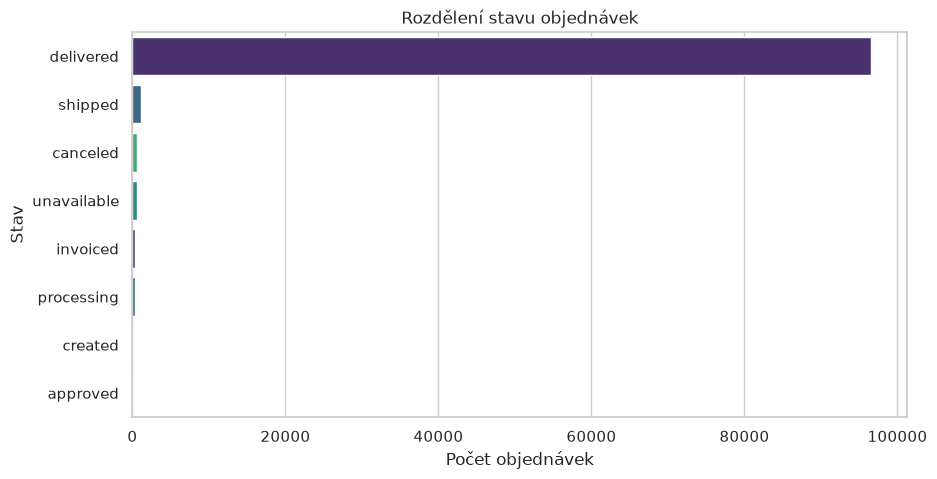

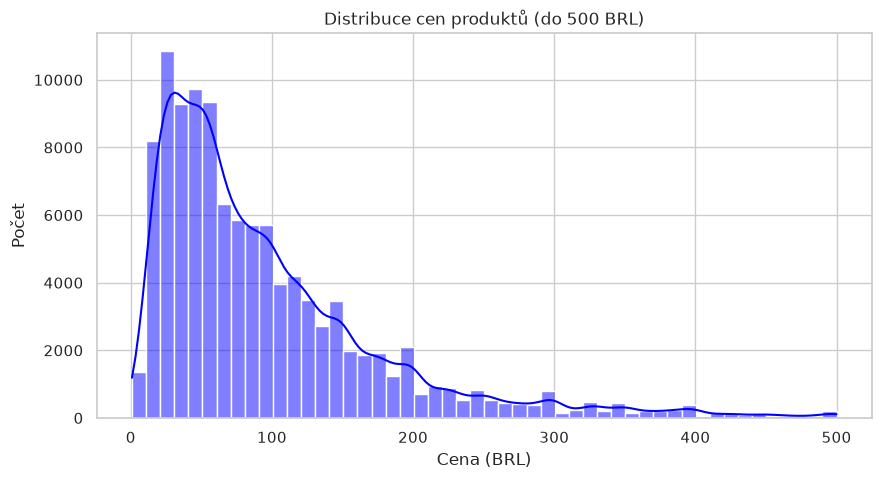

In [7]:
# Graf 1: Rozdělení stavu objednávek (kategoriální graf)
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_orders,
    y='order_status',
    hue='order_status', # Přidáno pro odstranění warningu
    order=df_orders['order_status'].value_counts().index,
    palette="viridis",
    legend=False # Přidáno pro odstranění warningu
)
plt.title('Rozdělení stavu objednávek')
plt.xlabel('Počet objednávek')
plt.ylabel('Stav')
plt.show()

# Graf 2: Distribuce ceny položek v objednávkách (s omezením na položky do 500 BRL pro přehlednost)
plt.figure(figsize=(10, 5))
sns.histplot(df_items[df_items['price'] < 500]['price'], bins=50, kde=True, color='blue')
plt.title('Distribuce cen produktů (do 500 BRL)')
plt.xlabel('Cena (BRL)')
plt.ylabel('Počet')
plt.show()